# Convolutional Recurrent Neural Network (CRNN)

In [4]:
from google.colab import drive
drive.mount("/content/drive")

import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים"
)

# This must be the directory that directly contains:
# train/, val/, and test/
PREPARED_DIR = PROJECT_DIR / "processed"

SAVE_DIR = PROJECT_DIR / "CRNN"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["choking", "laughter"]
CLASS_TO_INDEX = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

INPUT_SHAPE = (20, 128, 128)
NUM_CLASSES = len(CLASS_NAMES)

BATCH_SIZE = 4
EPOCHS = 15
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-3

MODEL_NAME = "laughvschoke_CRNN"

MODEL_SAVE_PATH = SAVE_DIR / f"{MODEL_NAME}_best.pth"
HISTORY_SAVE_PATH = SAVE_DIR / f"{MODEL_NAME}_history.json"
GRAPH_SAVE_PATH = SAVE_DIR / f"{MODEL_NAME}_training.png"
CONFUSION_SAVE_PATH = SAVE_DIR / f"{MODEL_NAME}_confusion_matrix.png"
PREDICTIONS_SAVE_PATH = SAVE_DIR / f"{MODEL_NAME}_predictions.csv"
RESULTS_SAVE_PATH = SAVE_DIR / f"{MODEL_NAME}_results.json"

print("Device:", device)
print("Prepared data directory:", PREPARED_DIR)
print("Results directory:", SAVE_DIR)

Device: cuda
Prepared data directory: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/processed
Results directory: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/CRNN


In [7]:
SUPPORTED_EXTENSIONS = {".npy"}


def collect_split_files(split_name):
    split_root = PREPARED_DIR / split_name
    records = []

    if not split_root.exists():
        raise FileNotFoundError(
            f"Split directory does not exist: {split_root}"
        )

    for class_name in CLASS_NAMES:
        class_directory = split_root / class_name

        if not class_directory.exists():
            raise FileNotFoundError(
                f"Class directory does not exist: {class_directory}"
            )

        class_files = sorted(
            path
            for path in class_directory.rglob("*")
            if (
                path.is_file()
                and path.suffix.lower() in SUPPORTED_EXTENSIONS
            )
        )

        print(
            f"{split_name:5s} | "
            f"{class_name:8s} | "
            f"{len(class_files)} files"
        )

        label = CLASS_TO_INDEX[class_name]

        for path in class_files:
            records.append(
                {
                    "path": path,
                    "label": label,
                    "class_name": class_name
                }
            )

    if len(records) == 0:
        raise ValueError(
            f"No .npy files were found inside {split_root}"
        )

    return records


train_records = collect_split_files("train")
val_records = collect_split_files("val")
test_records = collect_split_files("test")

print("\nTotal files:")
print("Training:", len(train_records))
print("Validation:", len(val_records))
print("Testing:", len(test_records))

train | choking  | 352 files
train | laughter | 288 files
val   | choking  | 34 files
val   | laughter | 46 files
test  | choking  | 34 files
test  | laughter | 25 files

Total files:
Training: 640
Validation: 80
Testing: 59


In [8]:
AUGMENTATION_SUFFIXES = [
    "_noise",
    "_ts0.85",
    "_ts1.15",
    "_ps-2",
    "_ps+2",
]


def get_original_recording_id(record):
    stem = record["path"].stem

    suffix_removed = True

    while suffix_removed:
        suffix_removed = False

        for suffix in AUGMENTATION_SUFFIXES:
            if stem.endswith(suffix):
                stem = stem[:-len(suffix)]
                suffix_removed = True
                break

    return f"{record['class_name']}/{stem}"


train_originals = {
    get_original_recording_id(record)
    for record in train_records
}

val_originals = {
    get_original_recording_id(record)
    for record in val_records
}

test_originals = {
    get_original_recording_id(record)
    for record in test_records
}

train_val_overlap = train_originals & val_originals
train_test_overlap = train_originals & test_originals
val_test_overlap = val_originals & test_originals

print("Train/validation overlap:", len(train_val_overlap))
print("Train/test overlap:", len(train_test_overlap))
print("Validation/test overlap:", len(val_test_overlap))

assert not train_val_overlap, (
    "Leakage detected between training and validation."
)

assert not train_test_overlap, (
    "Leakage detected between training and testing."
)

assert not val_test_overlap, (
    "Leakage detected between validation and testing."
)

print("\nNo original-recording leakage detected.")

Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0

No original-recording leakage detected.


In [9]:
class PreparedAudioDataset(Dataset):
    def __init__(
        self,
        records,
        expected_shape=(20, 128, 128)
    ):
        self.records = records
        self.expected_shape = expected_shape

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]

        feature_array = np.load(
            record["path"],
            allow_pickle=False
        )

        feature_array = np.asarray(
            feature_array,
            dtype=np.float32
        )

        # Convert (frequency, time, channels)
        # to (channels, frequency, time), if necessary.
        if feature_array.shape == (
            self.expected_shape[1],
            self.expected_shape[2],
            self.expected_shape[0]
        ):
            feature_array = np.transpose(
                feature_array,
                (2, 0, 1)
            )

        if feature_array.shape != self.expected_shape:
            raise ValueError(
                f"Unexpected tensor shape in {record['path']}.\n"
                f"Expected: {self.expected_shape}\n"
                f"Received: {feature_array.shape}"
            )

        # Replace invalid numerical values if any exist.
        feature_array = np.nan_to_num(
            feature_array,
            nan=0.0,
            posinf=0.0,
            neginf=0.0
        )

        x = torch.from_numpy(feature_array)
        y = torch.tensor(
            record["label"],
            dtype=torch.long
        )

        return x, y, str(record["path"])

In [10]:
train_dataset = PreparedAudioDataset(
    train_records,
    expected_shape=INPUT_SHAPE
)

val_dataset = PreparedAudioDataset(
    val_records,
    expected_shape=INPUT_SHAPE
)

test_dataset = PreparedAudioDataset(
    test_records,
    expected_shape=INPUT_SHAPE
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 640
Validation dataset: 80
Testing dataset: 59


In [11]:
PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=PIN_MEMORY
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 160
Validation batches: 20
Testing batches: 15


In [12]:
x_batch, y_batch, path_batch = next(
    iter(train_loader)
)

print("Input batch shape:", tuple(x_batch.shape))
print("Label batch shape:", tuple(y_batch.shape))
print("Input data type:", x_batch.dtype)
print("Labels:", y_batch.tolist())
print("First file:", path_batch[0])

assert x_batch.ndim == 4

assert tuple(x_batch.shape[1:]) == INPUT_SHAPE, (
    f"Expected batch samples with shape {INPUT_SHAPE}, "
    f"but received {tuple(x_batch.shape[1:])}."
)

print("\nPrepared data loaded successfully.")

Input batch shape: (4, 20, 128, 128)
Label batch shape: (4,)
Input data type: torch.float32
Labels: [0, 0, 1, 0]
First file: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/processed/train/choking/רח׳ קהילת קישינב 4 10__w1.npy

Prepared data loaded successfully.


In [13]:
class AudioCRNN(nn.Module):
    def __init__(
        self,
        input_channels=20,
        num_classes=2,
        gru_hidden_size=64
    ):
        super().__init__()

        self.cnn = nn.Sequential(
            # Input: (batch, 20, 128, 128)
            nn.Conv2d(
                input_channels,
                32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 2)),
            # Output: (batch, 32, 64, 64)

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 2)),
            # Output: (batch, 64, 32, 32)

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            # Reduce frequency, but preserve the time resolution.
            nn.MaxPool2d(kernel_size=(2, 1)),
            # Output: (batch, 128, 16, 32)

            nn.Dropout2d(0.20)
        )

        self.gru = nn.GRU(
            input_size=128,
            hidden_size=gru_hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.classifier = nn.Sequential(
            nn.Linear(gru_hidden_size * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.40),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # CNN output:
        # (batch, CNN channels, frequency, time)
        x = self.cnn(x)

        # Average over the frequency dimension:
        # (batch, CNN channels, time)
        x = x.mean(dim=2)

        # Convert to a sequence:
        # (batch, time, CNN channels)
        x = x.permute(0, 2, 1)

        # Recurrent processing:
        # (batch, time, 2 × GRU hidden size)
        x, _ = self.gru(x)

        # Combine the temporal outputs.
        x = x.mean(dim=1)

        # Final classification.
        logits = self.classifier(x)

        return logits

In [14]:
def count_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


model = AudioCRNN(
    input_channels=INPUT_SHAPE[0],
    num_classes=NUM_CLASSES,
    gru_hidden_size=64
).to(device)

print(model)
print("\nTrainable parameters:", f"{count_parameters(model):,}")

# Confirm that the architecture accepts the expected input.
with torch.no_grad():
    dummy_input = torch.zeros(
        2,
        *INPUT_SHAPE,
        device=device
    )

    dummy_output = model(dummy_input)

print("Test input shape:", tuple(dummy_input.shape))
print("Test output shape:", tuple(dummy_output.shape))

assert dummy_output.shape == (2, NUM_CLASSES)

print("\nCRNN architecture constructed successfully.")

AudioCRNN(
  (cnn): Sequential(
    (0): Conv2d(20, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=(2, 1), stride=(2, 1), padding=0, dilation=1, ceil_mode=False)
    (12): Dropout2d(p=0.2, inplace=False)
  )
  (gru): GRU(128, 64, batch_first=True, bidirectional=True)
  (classifier): Sequential(
    (0):

In [15]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=4
)

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "learning_rate": []
}

best_val_loss = float("inf")

In [16]:
def process_epoch(
    model,
    loader,
    criterion,
    device,
    optimizer=None
):
    is_training = optimizer is not None

    if is_training:
        model.train()
    else:
        model.eval()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    context = (
        torch.enable_grad()
        if is_training
        else torch.no_grad()
    )

    with context:
        for batch in loader:
            x = batch[0].to(
                device,
                dtype=torch.float32,
                non_blocking=True
            )

            y = batch[1].to(
                device,
                dtype=torch.long,
                non_blocking=True
            )

            if is_training:
                optimizer.zero_grad()

            logits = model(x)
            loss = criterion(logits, y)

            if is_training:
                loss.backward()
                optimizer.step()

            batch_size = y.size(0)

            running_loss += loss.item() * batch_size

            predictions = torch.argmax(logits, dim=1)
            correct_predictions += (
                predictions == y
            ).sum().item()

            total_samples += batch_size

    epoch_loss = running_loss / total_samples
    epoch_accuracy = correct_predictions / total_samples

    return epoch_loss, epoch_accuracy

In [17]:
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = process_epoch(
        model=model,
        loader=train_loader,
        criterion=criterion,
        device=device,
        optimizer=optimizer
    )

    val_loss, val_acc = process_epoch(
        model=model,
        loader=val_loader,
        criterion=criterion,
        device=device
    )

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["learning_rate"].append(current_lr)

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            {
                "model_name": MODEL_NAME,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "input_shape": INPUT_SHAPE,
                "class_names": CLASS_NAMES,
                "params": count_parameters(model),
                "epoch": epoch,
                "best_val_loss": best_val_loss,
                "val_accuracy": val_acc,
                "architecture": "CNN-BiGRU",
                "gru_hidden_size": 64,
            },
            MODEL_SAVE_PATH
        )

        best_marker = "  <-- best saved"
    else:
        best_marker = ""

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {train_loss:.4f}, "
        f"acc {train_acc:.4f} | "
        f"val loss {val_loss:.4f}, "
        f"acc {val_acc:.4f} | "
        f"lr {current_lr:.2e}"
        f"{best_marker}"
    )


with open(HISTORY_SAVE_PATH, "w") as file:
    json.dump(history, file, indent=4)

print("\nBest model saved to:")
print(MODEL_SAVE_PATH)

print("\nTraining history saved to:")
print(HISTORY_SAVE_PATH)

assert MODEL_SAVE_PATH.exists(), "The model checkpoint was not saved."

Epoch 01/15 | train loss 0.6068, acc 0.6750 | val loss 0.5133, acc 0.7875 | lr 5.00e-04  <-- best saved
Epoch 02/15 | train loss 0.5398, acc 0.7422 | val loss 0.5526, acc 0.7125 | lr 5.00e-04
Epoch 03/15 | train loss 0.4909, acc 0.7625 | val loss 0.4685, acc 0.7750 | lr 5.00e-04  <-- best saved
Epoch 04/15 | train loss 0.4843, acc 0.7859 | val loss 0.6440, acc 0.6250 | lr 5.00e-04
Epoch 05/15 | train loss 0.4613, acc 0.7969 | val loss 0.5586, acc 0.7250 | lr 5.00e-04
Epoch 06/15 | train loss 0.4247, acc 0.8016 | val loss 0.5450, acc 0.7375 | lr 5.00e-04
Epoch 07/15 | train loss 0.4122, acc 0.8297 | val loss 0.5222, acc 0.7750 | lr 5.00e-04
Epoch 08/15 | train loss 0.4217, acc 0.8156 | val loss 0.3936, acc 0.8125 | lr 5.00e-04  <-- best saved
Epoch 09/15 | train loss 0.3886, acc 0.8359 | val loss 0.4770, acc 0.7750 | lr 5.00e-04
Epoch 10/15 | train loss 0.3271, acc 0.8828 | val loss 0.3464, acc 0.8500 | lr 5.00e-04  <-- best saved
Epoch 11/15 | train loss 0.3004, acc 0.8906 | val loss 0

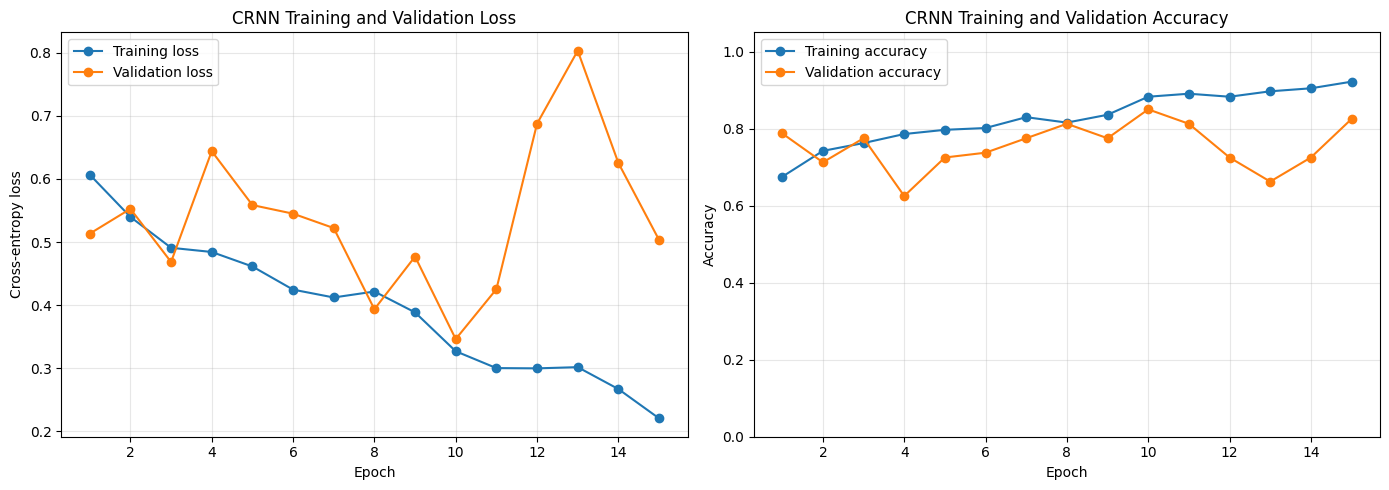

Training graph saved to:
/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/CRNN/laughvschoke_CRNN_training.png


In [18]:
epoch_numbers = range(
    1,
    len(history["train_loss"]) + 1
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Loss graph
axes[0].plot(
    epoch_numbers,
    history["train_loss"],
    marker="o",
    label="Training loss"
)

axes[0].plot(
    epoch_numbers,
    history["val_loss"],
    marker="o",
    label="Validation loss"
)

axes[0].set_title("CRNN Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Accuracy graph
axes[1].plot(
    epoch_numbers,
    history["train_acc"],
    marker="o",
    label="Training accuracy"
)

axes[1].plot(
    epoch_numbers,
    history["val_acc"],
    marker="o",
    label="Validation accuracy"
)

axes[1].set_title("CRNN Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.05)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()

plt.savefig(
    GRAPH_SAVE_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Training graph saved to:")
print(GRAPH_SAVE_PATH)

In [19]:
checkpoint = torch.load(
    MODEL_SAVE_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

all_predictions = []
all_labels = []
all_paths = []

with torch.no_grad():
    for batch_number, batch in enumerate(test_loader):
        x = batch[0].to(
            device,
            dtype=torch.float32,
            non_blocking=True
        )

        y = batch[1]

        logits = model(x)
        predictions = torch.argmax(
            logits,
            dim=1
        ).cpu()

        all_predictions.extend(
            predictions.numpy().tolist()
        )

        all_labels.extend(
            y.numpy().tolist()
        )

        if len(batch) >= 3:
            all_paths.extend(
                [str(path) for path in batch[2]]
            )
        else:
            first_index = len(all_paths)

            all_paths.extend(
                [
                    f"test_sample_{first_index + i}"
                    for i in range(len(y))
                ]
            )


test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )
)

print("Model:", checkpoint["model_name"])
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", f"{checkpoint['best_val_loss']:.4f}")
print("Parameter count:", f"{checkpoint['params']:,}")
print("Test accuracy:", f"{test_accuracy:.4f}")

print("\nClassification report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

Model: laughvschoke_CRNN
Best epoch: 10
Best validation loss: 0.3464
Parameter count: 181,474
Test accuracy: 0.8305

Classification report:

              precision    recall  f1-score   support

     choking     0.9286    0.7647    0.8387        34
    laughter     0.7419    0.9200    0.8214        25

    accuracy                         0.8305        59
   macro avg     0.8353    0.8424    0.8301        59
weighted avg     0.8495    0.8305    0.8314        59



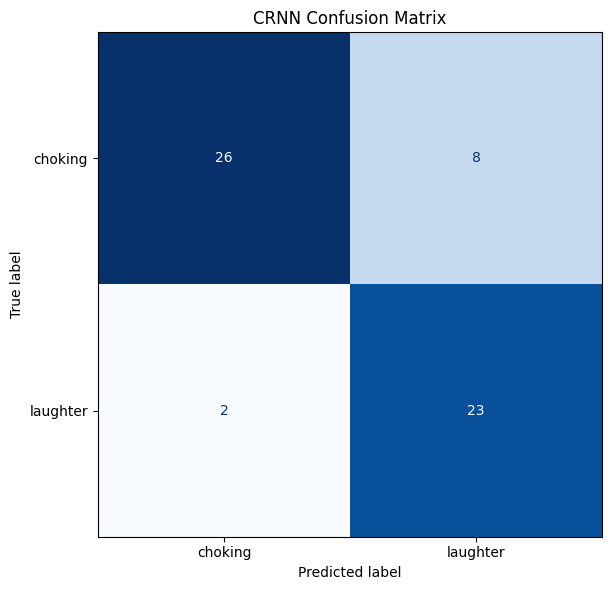

Confusion matrix:
[[26  8]
 [ 2 23]]

Confusion matrix saved to:
/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/CRNN/laughvschoke_CRNN_confusion_matrix.png


In [20]:
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(NUM_CLASSES))
)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

fig, ax = plt.subplots(figsize=(7, 6))

cm_display.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

ax.set_title("CRNN Confusion Matrix")
plt.tight_layout()

plt.savefig(
    CONFUSION_SAVE_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix:")
print(cm)

print("\nConfusion matrix saved to:")
print(CONFUSION_SAVE_PATH)

In [21]:
prediction_table = pd.DataFrame(
    {
        "file": all_paths,
        "true_label_index": all_labels,
        "true_label": [
            CLASS_NAMES[label]
            for label in all_labels
        ],
        "predicted_label_index": all_predictions,
        "predicted_label": [
            CLASS_NAMES[prediction]
            for prediction in all_predictions
        ],
    }
)

prediction_table["correct"] = (
    prediction_table["true_label_index"]
    == prediction_table["predicted_label_index"]
)

prediction_table.to_csv(
    PREDICTIONS_SAVE_PATH,
    index=False
)

report_dictionary = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

experiment_results = {
    "model_name": MODEL_NAME,
    "architecture": "CNN-BiGRU",
    "best_epoch": int(checkpoint["epoch"]),
    "parameter_count": int(checkpoint["params"]),
    "best_validation_loss": float(
        checkpoint["best_val_loss"]
    ),
    "test_accuracy": float(test_accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "confusion_matrix": cm.tolist(),
    "classification_report": report_dictionary,
}

with open(RESULTS_SAVE_PATH, "w") as file:
    json.dump(
        experiment_results,
        file,
        indent=4
    )

print("Predictions saved to:")
print(PREDICTIONS_SAVE_PATH)

print("\nNumerical results saved to:")
print(RESULTS_SAVE_PATH)

print("\nMisclassified recordings:")

display(
    prediction_table[
        prediction_table["correct"] == False
    ]
)

Predictions saved to:
/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/CRNN/laughvschoke_CRNN_predictions.csv

Numerical results saved to:
/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/CRNN/laughvschoke_CRNN_results.json

Misclassified recordings:


,file,true_label_index,true_label,predicted_label_index,predicted_label,correct
4,/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשי...,0,choking,1,laughter,False
9,/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשי...,0,choking,1,laughter,False
10,/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשי...,0,choking,1,laughter,False
16,/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשי...,0,choking,1,laughter,False
19,/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשי...,0,choking,1,laughter,False
20,/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשי...,0,choking,1,laughter,False
22,/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשי...,0,choking,1,laughter,False
23,/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשי...,0,choking,1,laughter,False
44,/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשי...,1,laughter,0,choking,False
52,/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשי...,1,laughter,0,choking,False


In [22]:
summary_table = pd.DataFrame(
    [
        {
            "Architecture": "CRNN (CNN-BiGRU)",
            "Parameters": checkpoint["params"],
            "Best epoch": checkpoint["epoch"],
            "Test accuracy": test_accuracy,
            "Macro precision": macro_precision,
            "Macro recall": macro_recall,
            "Macro F1": macro_f1,
        }
    ]
)

summary_table.style.format(
    {
        "Parameters": "{:,}",
        "Test accuracy": "{:.4f}",
        "Macro precision": "{:.4f}",
        "Macro recall": "{:.4f}",
        "Macro F1": "{:.4f}",
    }
)

,Architecture,Parameters,Best epoch,Test accuracy,Macro precision,Macro recall,Macro F1
0,CRNN (CNN-BiGRU),"181,474",10,0.8305,0.8353,0.8424,0.8301
